In [1]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
from statsmodels.api import OLS
import sklearn.model_selection as skm
import sklearn.linear_model as skl
from sklearn.preprocessing import StandardScaler
from ISLP import load_data
from ISLP.models import ModelSpec as MS
from functools import partial

In [2]:
from sklearn.pipeline import Pipeline #step-by-step recipe
from sklearn.decomposition import PCA #It reduces the number of features by combining them into new ones (called principal components) that keep the most important information.
from sklearn.cross_decomposition import PLSRegression #Partial Least Squares Regression, selects variables explain variance
from ISLP.models import \
     (Stepwise,
      sklearn_selected,
      sklearn_selection_path)
from l0bnb import fit_path #does subset selection (finds the path)
import statsmodels.api as sm

In [3]:
df = pd.read_stata("bechtel_liesch_scheve_pnas.dta")
df

,weight,IA1,IA2,age,male,advantagIneq,disadvantagIneq,equality,heavyTaxes,notlessBenefits,...,a_nonequalizer,a_equalizer,d_other_alt,d_nonequalizer_alt,d_equalizer_alt,a_other_alt,a_nonequalizer_alt,a_equalizer_alt,d_sensitivity,a_sensitivity
0,0.972545,25,75,59,female,0,1,0,4,4,...,1,0,0,1,0,0,1,0,0.087267,0.000000
1,1.543672,50,50,59,female,0,0,1,3,4,...,1,0,0,1,0,0,1,0,0.000000,0.000000
2,1.220596,75,25,23,male,1,0,0,4,4,...,0,0,1,0,0,1,0,0,2.250000,-0.315528
3,1.485086,25,75,29,female,0,1,0,4,3,...,0,1,0,0,1,0,0,1,0.223602,0.250000
4,0.486945,25,75,25,male,0,1,0,3,3,...,0,1,0,0,1,0,0,1,0.425776,0.350000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4961,0.814561,50,50,21,female,0,0,1,Strongly agree,Strongly agree,...,1,0,0,0,1,0,1,0,0.616760,0.106145
4962,0.751945,50,50,21,male,0,0,1,Strongly agree,Strongly disagree,...,1,0,0,1,0,0,1,0,0.000000,0.000000
4963,1.709338,25,75,66,female,0,1,0,Strongly agree,4,...,1,0,0,0,1,0,1,0,0.309006,0.000000
4964,1.151964,75,25,65,female,1,0,0,4,4,...,0,0,1,0,0,1,0,0,1.000000,1.069876


In [ ]:
X = [
    "taken", "advantagIneq", "age", "male", "GE",
    "inc_low", "inc_middle",
    "edu_low", "edu_middle",
    "left_ideology", "right_ideology",
    "employed", "unemployed", "retired", "inEducation" 
]


df2 = df.loc[
    (df["advantagIneq"] == 1) | (df["equality"] == 1),
    X
].dropna().copy()

In [20]:
model = MS(df2.columns.drop("taken"), intercept=True)
D = model.fit_transform(df2).drop(columns="intercept")

X = D.to_numpy(dtype=float)
Y = np.asarray(df2["taken"], dtype=float)

# Standardize for coefficient paths
Xs = StandardScaler().fit_transform(X)

K = 5
kfold = skm.KFold(K, shuffle=True, random_state=0)

In [21]:
lassoCV = skl.ElasticNetCV(n_alphas=100, l1_ratio=1, cv=kfold)
pipeCV  = Pipeline([('scaler', StandardScaler()), ('lasso', lassoCV)]).fit(X, Y)
tuned_lasso = pipeCV.named_steps['lasso']
tuned_lasso.alpha_, np.min(tuned_lasso.mse_path_.mean(1))
(tuned_lasso.coef_ == 0).sum()                       # how many variables dropped
lambdas, soln_array = skl.Lasso.path(Xs, Y, l1_ratio=1, n_alphas=100)[:2]
soln_path = pd.DataFrame(soln_array.T,
                         columns=D.columns,
                         index=-np.log(lambdas))

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:1663: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


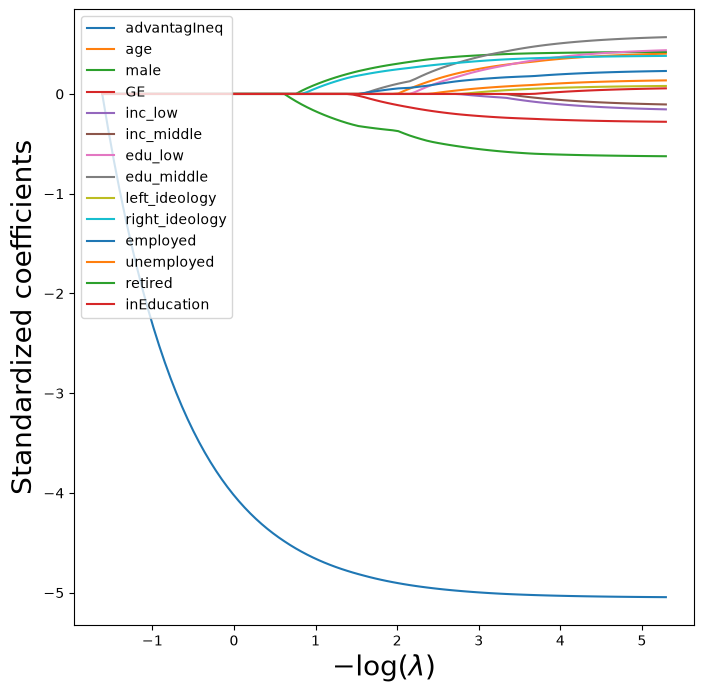

In [22]:
path_fig, ax = subplots(figsize=(8,8))
soln_path.plot(ax=ax, legend=False)
ax.legend(loc='upper left')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20);

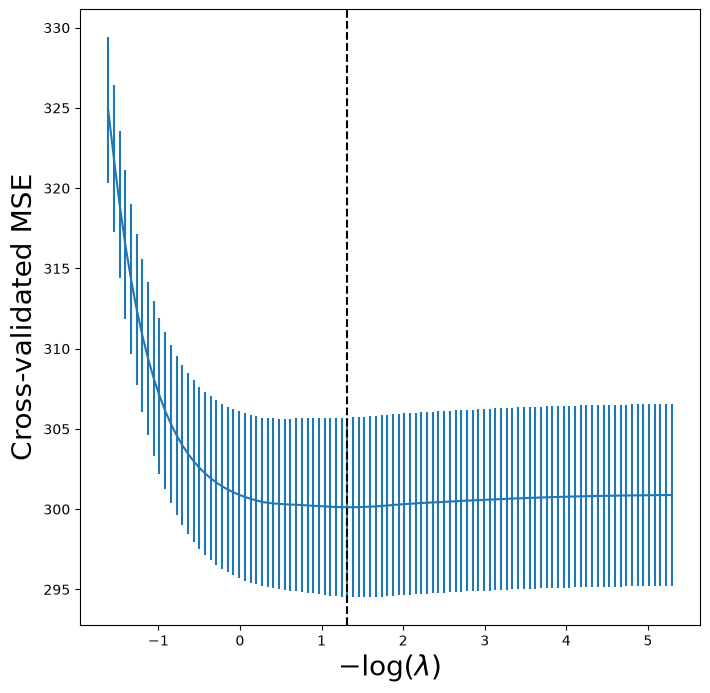

In [25]:
lassoCV_fig, ax = subplots(figsize=(8,8))
ax.errorbar(-np.log(tuned_lasso.alphas_),
            tuned_lasso.mse_path_.mean(1),
            yerr=tuned_lasso.mse_path_.std(1) / np.sqrt(K))
ax.axvline(-np.log(tuned_lasso.alpha_), c='k', ls='--')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20);

In [ ]:
tuned_lasso.alpha_
tuned_lasso.coef_